# Save/load street network models to/from disk

From [THIS url](https://github.com/gboeing/osmnx-examples/blob/main/notebooks/05-save-load-networks.ipynb)

Author: [Geoff Boeing](https://geoffboeing.com/)

  - [Documentation](https://osmnx.readthedocs.io/)
  - [Journal article and citation info](https://doi.org/10.1111/gean.70009)
  - [Code repository](https://github.com/gboeing/osmnx)
  - [Examples gallery](https://github.com/gboeing/osmnx-examples)
  
This notebook demonstrates how to save networks to disk as GeoPackages, GraphML files, and .osm formatted XML, and how to load an OSMnx-created network from a GraphML file.

In [2]:
from pathlib import Path

import osmnx as ox

ox.settings.log_console = True
ox.__version__

'2.1.1'

In [3]:
place = "Stanford, California, USA"
G = ox.graph.graph_from_place(place, network_type="drive")

## GeoPackages for GIS

In [4]:
# save graph as a geopackage
ox.io.save_graph_geopackage(G, filepath="./data/stanford.gpkg")

## GraphML files for saving network and preserving topological detail

In [5]:
# save/load graph as a graphml file: this is the best way to save your model
# for subsequent work later
filepath = "./data/stanford.graphml"
ox.io.save_graphml(G, filepath)
G = ox.io.load_graphml(filepath)

In [6]:
# if you want to work with your model in gephi, use gephi compatibility mode
ox.io.save_graphml(G, filepath=filepath, gephi=True)

## SVG file to work with in Adobe Illustrator

In [8]:
# save street network as SVG
fig, ax = ox.plot.plot_graph(G, show=False, save=True, close=True, filepath="./images/stanford.svg")

## Urban amenities: save points of interest, building footprints, etc

In [9]:
Path("data").mkdir(parents=True, exist_ok=True)

In [18]:
# get all "amenities" and save as a geopackage via geopandas
gdf = ox.features.features_from_place(place, tags={"amenity": True})
gdf = gdf.apply(lambda c: c.astype(str) if c.name != "geometry" else c, axis=0)
gdf.to_file("./data/stanford_pois.gpkg", driver="GPKG")

In [19]:
# get all building footprints and save as a geopackage via geopandas
gdf = ox.features.features_from_place(place, tags={"building": True})
gdf = gdf.apply(lambda c: c.astype(str) if c.name != "geometry" else c, axis=0)
gdf.to_file("./data/stanford_building_footprints.gpkg", driver="GPKG")

## Save OSM XML files

To save your graph to disk as a .osm formatted XML file, ensure that you created the graph with `ox.settings.all_oneway=True` for `save_graph_xml` to work properly. See docstring for details.

To save/load full-featured OSMnx graphs to/from disk for later use, use the `save_graphml` and `load_graphml` functions instead.

In [12]:
# save graph to disk as .osm xml file
ox.settings.all_oneway = True
G = ox.graph.graph_from_place("Stanford, California, USA", network_type="drive", simplify=False)
ox.io.save_graph_xml(G, filepath="./data/stanford.osm")

## PLOT EVERYTHING

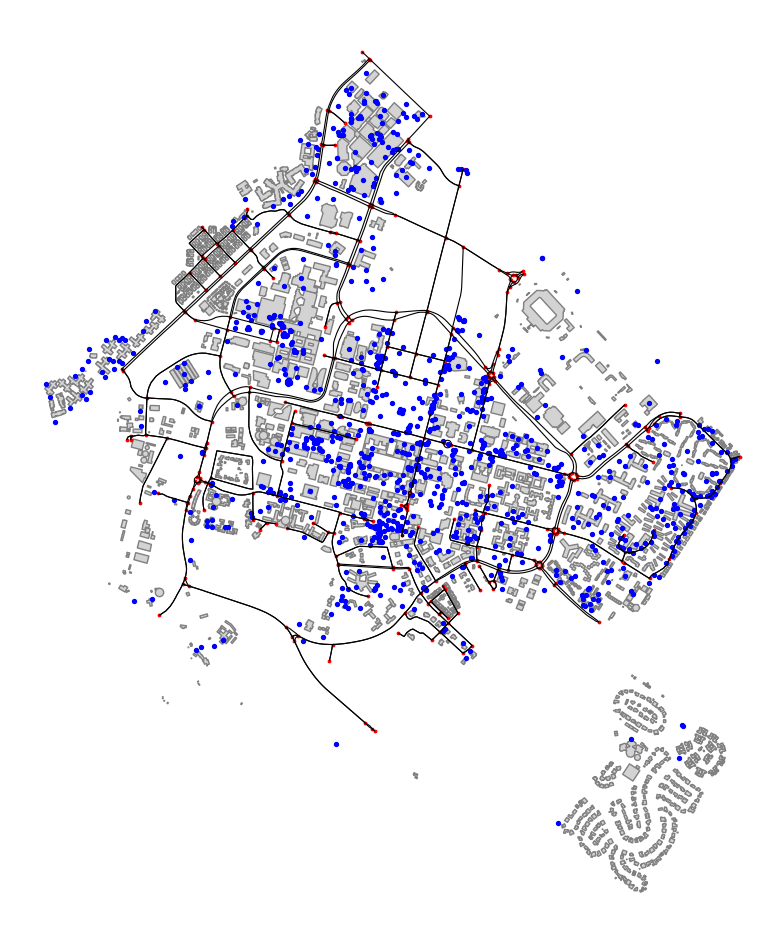

In [20]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Load road network
G = ox.load_graphml("data/stanford.graphml")
G = ox.project_graph(G)

nodes, edges = ox.graph_to_gdfs(G)

# Load geographic features
buildings = gpd.read_file("data/stanford_building_footprints.gpkg")
pois = gpd.read_file("data/stanford_pois.gpkg")

# Convert everything to the same coordinate system
buildings = buildings.to_crs(edges.crs)
pois = pois.to_crs(edges.crs)

# Plot
fig, ax = plt.subplots(figsize=(12, 12))

buildings.plot(ax=ax, color="lightgray", edgecolor="gray")
edges.plot(ax=ax, color="black", linewidth=0.8)
nodes.plot(ax=ax, color="red", markersize=3)

# Represent amenities with points, even if their geometry is a polygon
pois.geometry.representative_point().plot(
    ax=ax, color="blue", markersize=8
)

ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [51]:
node = next(iter(G.nodes))

print(node)           # OSM node ID (integer)
print(hash(node))     # Already hashable
print(G.nodes[node])  # Node attributes

edge = next(iter(G.edges))

print()
print(edge)           # OSM edge ID (integer)
print(hash(edge))     # Already hashable
print(G.edges[edge])  # Node attributes

65381218
65381218
{'y': 4143345.146977279, 'x': 573211.2847432281, 'street_count': 3}

(65381218, 689482700, 0)
-2943713231458920922
{'osmid': 698085639, 'highway': 'tertiary', 'lanes': '3', 'maxspeed': '25 mph', 'name': 'Campus Drive', 'oneway': True, 'reversed': False, 'length': 18.610464179315347}
